
#  SPI Interfaces and the Physics of Clock Domain Crossings

## 1. What is SPI (Serial Peripheral Interface)?
Before we build the parser for Lab 4, we need to understand how the data actually arrives at the FPGA. The Raspberry Pi Pico communicates with our FPGA using **SPI (Serial Peripheral Interface)**. 

SPI is a synchronous, serial communication protocol primarily used for short-distance communication in embedded systems. Unlike asynchronous serial (like UART or standard RS-232) which relies on precise, agreed-upon baud rates, SPI includes a dedicated clock line to dictate exactly when data should be read.

An SPI bus consists of one **Master** (the controller, our Pico) and one or more **Slaves** (the peripherals, our FPGA). It uses four dedicated wires:
*   **SCK (Serial Clock):** Generated by the Master. This clock toggles only when data is actively being transferred.
*   **CSN (Chip Select Not / Active-Low):** Generated by the Master. The Master pulls this line LOW (0V) to tell the Slave, *"Wake up, I am talking to you now."* When it goes HIGH, the transaction is over.
*   **MOSI (Master Out, Slave In):** The data wire sending bits from the Pico to the FPGA.
*   **MISO (Master In, Slave Out):** The data wire sending bits from the FPGA back to the Pico. 

**How a Transfer Works:**
When the Pico wants to send a command, it pulls `CSN` LOW. Then, it starts toggling `SCK`. On every clock cycle, one bit of data is shifted out onto `MOSI`, and one bit is shifted in from `MISO`. It acts essentially like a giant, distributed shift register. When the command is finished, the Pico stops the clock and pulls `CSN` HIGH. 

In Lab 4, the Pico blasts SPI data at roughly 33 MHz. Your FPGA will listen to `MOSI` on the rising edge of `SCK`.

---

## 2. The Clock Domain Crossing (CDC) Problem
Here is where things get dangerous. Our SPI data arrives pushed by a **33 MHz SPI Clock**. However, your radio's DSP math and internal state machines are running continuously on a completely separate, free-running **30.72 MHz Master Clock**. 

When data moves from one clock speed to another, we call this a **Clock Domain Crossing (CDC)**. 

### The Digital Abstraction Fallacy
Recall from digital logic that D-Flip-Flops have strict timing requirements:
*   **Setup Time ($t_{su}$):** Data must be stable before the clock edge.
*   **Hold Time ($t_{h}$):** Data must remain stable after the clock edge.

Because our 33 MHz and 30.72 MHz clocks have completely independent oscillators, they are asynchronous to each other. Their rising edges will inevitably drift past one another, meaning the 30.72 MHz clock *will* eventually sample the SPI data exactly as it is transitioning. We will violate setup and hold times.

It is tempting to rely on the digital abstraction and assume: *"Even if we violate setup/hold, the register will just take a little longer (its propagation delay) and eventually spit out a valid 0 or a 1."* 

**This assumption is entirely false.** We cannot build a synchronizer that guarantees a valid digital output in a bounded amount of time. To understand why, we have to look inside the silicon.

---

## 3. The Physics of Metastability
If we strip away the digital abstraction, the master latch inside a D-Flip-Flop is simply a multiplexer that closes a positive feedback loop (essentially two inverters wired in a ring) to hold a memory state.

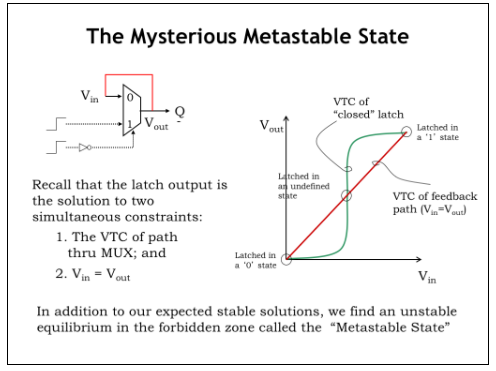

This two-gate cyclic circuit is governed by its Voltage Transfer Characteristic (VTC) curve, alongside the constraint that $V_{in} = V_{out}$. If you plot these two curves, they intersect at exactly three points:
1.  **Stable 0** (e.g., 0 Volts)
2.  **Stable 1** (e.g., $V_{DD}$)
3.  **An Unstable Equilibrium** (exactly in the middle, around $V_{DD}/2$)

If the asynchronous input and the clock edge transition at the exact same time, the latch closes the feedback loop right as the internal voltage is sitting at that middle intersection point. The system is caught in an unstable equilibrium. We call this the **Metastable State**.

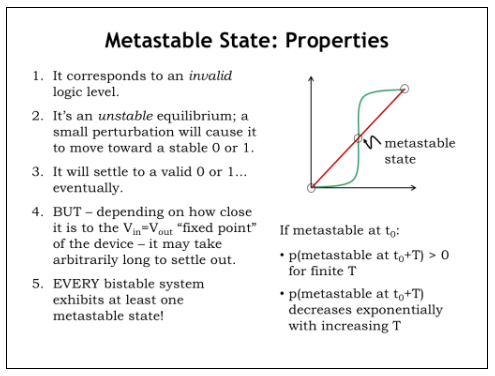

### The Consequences of Metastability
In theory, the register could balance perfectly at this metastable voltage forever. In reality, tiny thermal noise or voltage perturbations will eventually nudge the loop away from the center, sending it irrevocably sliding down the VTC curve toward a stable 0 or 1.

However, the closer the initial voltage was to the exact metastable point, the longer it takes to resolve. Because there is no lower bound on how close the initial voltage can be to the center, **there is no upper bound on how long it will take to resolve.** 

While the register is stuck balancing in this metastable state, two disastrous things happen:
1.  **Logical Havoc:** The output voltage is in the "forbidden zone." Downstream logic gates might interpret it differently—some reading a 0, some reading a 1—corrupting the FSM state.
2.  **Electrical Havoc:** At $V_{DD}/2$, both the PFET and NFET transistors inside the receiving CMOS gates are partially conducting. This creates a direct short-circuit path between $V_{DD}$ and Ground, causing a massive spike in power dissipation.

---

## 4. The Solution: Quarantine and Exponential Decay
Because every bistable storage element relies on positive feedback, metastability is a physical inevitability. We cannot prevent the first receiving flip-flop from going metastable. 

Instead of trying to *prevent* it, we **quarantine** it using a **2-Flop Synchronizer**.

1.  **Stage 1 (The Catcher):** The asynchronous signal is clocked into a 30.72 MHz flip-flop. We accept that this flop will occasionally go metastable.
2.  **The Quarantine:** We do *not* route this signal to our internal logic. In fact, we don't look at it at all. We just let the signal sit on a wire for an entire clock period.
3.  **Stage 2 (The Cleaner):** On the *next* 30.72 MHz clock edge, a second flip-flop samples the output of the first flop. 

**Why does this work?**
While we cannot mathematically bound the resolution time, the probability of a signal *remaining* metastable decreases **exponentially** with time. By locking the signal in quarantine for an entire 30 MHz clock period (roughly 32 nanoseconds), we give the transistor physics time to resolve. 

Giving the signal one full clock cycle to settle takes the Mean Time Between Failures (MTBF) of your radio from a few hours to several decades. 

*(Note: We only pass single-bit toggle flags through a synchronizer! To pass a 32-bit data bus, you hold the 32-bit bus completely steady, pass a single "Data Ready" flag through the 2-flop synchronizer, and only let the Master domain read the 32-bit bus once the synchronized flag tells it the data is safe to look at.)*

---

## 5. Writing the Synchronizer in SystemVerilog
Let's look at how we actually describe this 2-Flop Synchronizer circuit in SystemVerilog. 

Remember: **You are not writing software.** You are drawing a circuit blueprint using text. SystemVerilog does not execute line-by-line; it describes hardware that runs in parallel.

```systemverilog
module synchronizer (
    input  logic clk_30m,     // The receiving clock domain
    input  logic async_in,    // The dangerous, asynchronous signal
    output logic sync_out     // The clean, synchronized signal
);

    // This logic wire connects the output of Flop 1 to the input of Flop 2
    logic stage1_quarantine; 

    // The always_ff block tells the synthesizer to build D-Flip-Flops
    always_ff @(posedge clk_30m) begin
        stage1_quarantine <= async_in;          // Flop 1 catches the asynchronous signal
        sync_out          <= stage1_quarantine; // Flop 2 samples the quarantined signal
    end

endmodule
```

### Breaking down the code (The Hardware View):
1.  **`logic stage1_quarantine;`** 
    Think of `logic` as a physical copper wire. We are declaring a wire to connect the output pin of our first Flip-Flop to the input pin of our second Flip-Flop.
2.  **`always_ff @(posedge clk_30m) begin`**
    This block is the most important concept in Verilog. It tells the compiler: *"Look at the code inside this block, and synthesize physical edge-triggered D-Flip-Flops. Connect their clock pins to the `clk_30m` wire."* 
3.  **The Non-Blocking Assignment (`<=`)**
    Notice we use `<=` instead of `=`. In hardware, all Flip-Flops sharing a clock edge update at the exact same physical instant. The `<=` operator dictates that all assignments happen **in parallel**. 
    *   `stage1_quarantine` gets the *old* value of `async_in` (catching the signal).
    *   At the exact same picosecond, `sync_out` gets the *old* value of `stage1_quarantine` (sampling the settled signal).
    
    If this were a C program using `=`, `stage1_quarantine` would update first, and `sync_out` would immediately equal the new `async_in`. But because this is hardware using `<=`, it takes exactly **two clock cycles** for a change on `async_in` to propagate out of `sync_out`. We have successfully created a 2-stage shift register to quarantine our metastable signals!